In [ ]:
# R Data Cleaning and Visualization - 10/23/2026 - JerDea2641

In [5]:
# Load required packages
library(readxl)
library(writexl)
library(ggplot2)
library(corrplot)

# Load the Airbnb dataset
file_path <- "C:/Users/Jeremy/Downloads/AirBnBSummary_v2.xlsx"
df <- read_excel(file_path)

# Display the first few rows
head(df)

corrplot 0.95 loaded



id,host_id,host_name,neighbourhood,room_type,price,minimum_nights,number_of_reviews,availability_365,<StudentID>
<dbl>,<dbl>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>
7909479,41706311,David,Downtown,Entire home/apt,107,30,27,365,NA
15966488,103700433,Erin,Downtown,Entire home/apt,100,1,250,74,NA
19859814,103700433,Erin,Downtown,Entire home/apt,100,1,309,79,NA
21071138,22992627,Joseph,Downtown,Entire home/apt,100,2,144,338,NA
21712505,103700433,Erin,Downtown,Entire home/apt,100,1,178,68,NA
25771375,140728885,Rick,Downtown,Entire home/apt,95,2,216,246,NA


In [7]:
# Remove duplicate entries
df <- unique(df)

# Correct room type spelling
df$room_type[df$room_type == "Private room"] <- "Private Room"

# Display the number of listings remaining
nrow(df)

[1] 1775

In [8]:
# Fill missing numeric values using the median
numeric_columns <- names(df)[sapply(df, is.numeric)]

for (column in numeric_columns) {
  df[[column]][is.na(df[[column]])] <-
    median(df[[column]], na.rm = TRUE)
}

In [9]:
# Remove outliers using the IQR method
numeric_columns <- names(df)[sapply(df, is.numeric)]
outlier_rows <- rep(FALSE, nrow(df))

for (column in numeric_columns) {
  Q1 <- quantile(df[[column]], 0.25, na.rm = TRUE)
  Q3 <- quantile(df[[column]], 0.75, na.rm = TRUE)
  IQR_value <- IQR(df[[column]], na.rm = TRUE)

  lower_bound <- Q1 - 1.5 * IQR_value
  upper_bound <- Q3 + 1.5 * IQR_value

  outlier_rows <- outlier_rows |
    (df[[column]] < lower_bound |
     df[[column]] > upper_bound)
}

df <- df[!outlier_rows, ]

# Display remaining listings
nrow(df)

[1] 1205

In [10]:
# Save the cleaned dataset to Excel
write_xlsx(
  df,
  "C:/Users/Jeremy/Downloads/AirBnBSummary_v2_R_Cleaned.xlsx"
)

In [11]:
# Display required statistics
cat("Total count of listings:", nrow(df), "\n")
cat("Minimum price:", min(df$price, na.rm = TRUE), "\n")
cat("Maximum price:", max(df$price, na.rm = TRUE), "\n")
cat("Mean price of listings:", mean(df$price, na.rm = TRUE), "\n")

cat("Median number_of_reviews:",
    median(df$number_of_reviews, na.rm = TRUE), "\n")

# Mode of minimum_nights
mode_values <- unique(df$minimum_nights)
mode_value <- mode_values[
  which.max(tabulate(match(df$minimum_nights, mode_values)))
]
cat("Mode of minimum_nights:", mode_value, "\n")

cat("Standard deviation of price:",
    sd(df$price, na.rm = TRUE), "\n")

cat("Correlation between price and availability_365:",
    cor(df$price, df$availability_365, use = "complete.obs"), "\n")

Total count of listings: 1205 
Minimum price: 32 
Maximum price: 308 
Mean price of listings: 132.1801 
Median number_of_reviews: 20 
Mode of minimum_nights: 1 
Standard deviation of price: 62.53379 
Correlation between price and availability_365: 0.09281346 


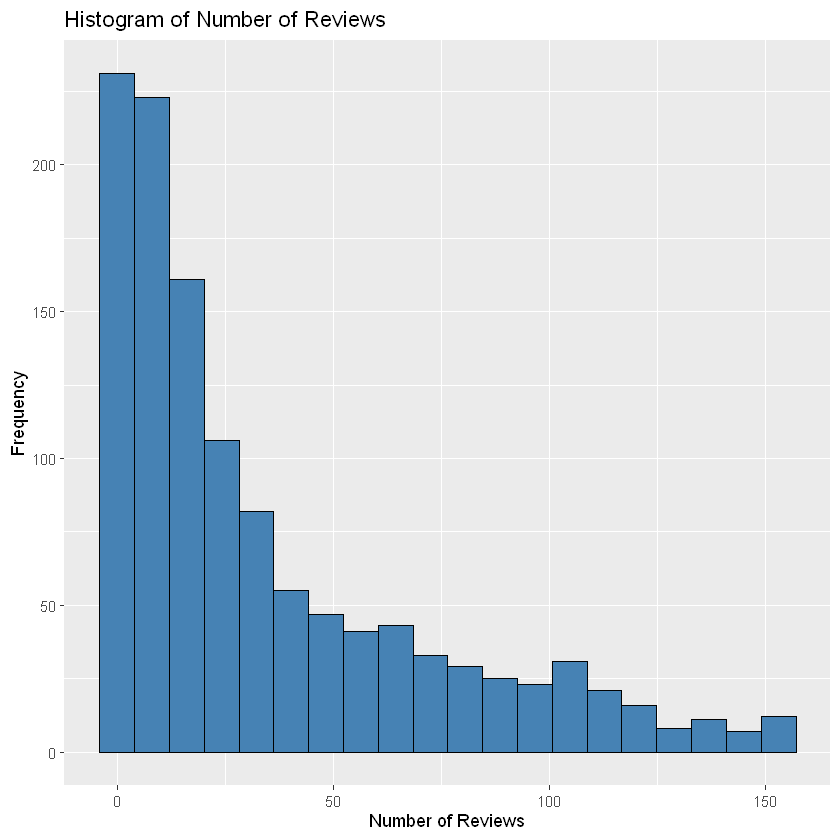

In [12]:
# Histogram of number_of_reviews
ggplot(df, aes(x = number_of_reviews)) +
  geom_histogram(bins = 20, fill = "steelblue", color = "black") +
  labs(
    title = "Histogram of Number of Reviews",
    x = "Number of Reviews",
    y = "Frequency"
  )

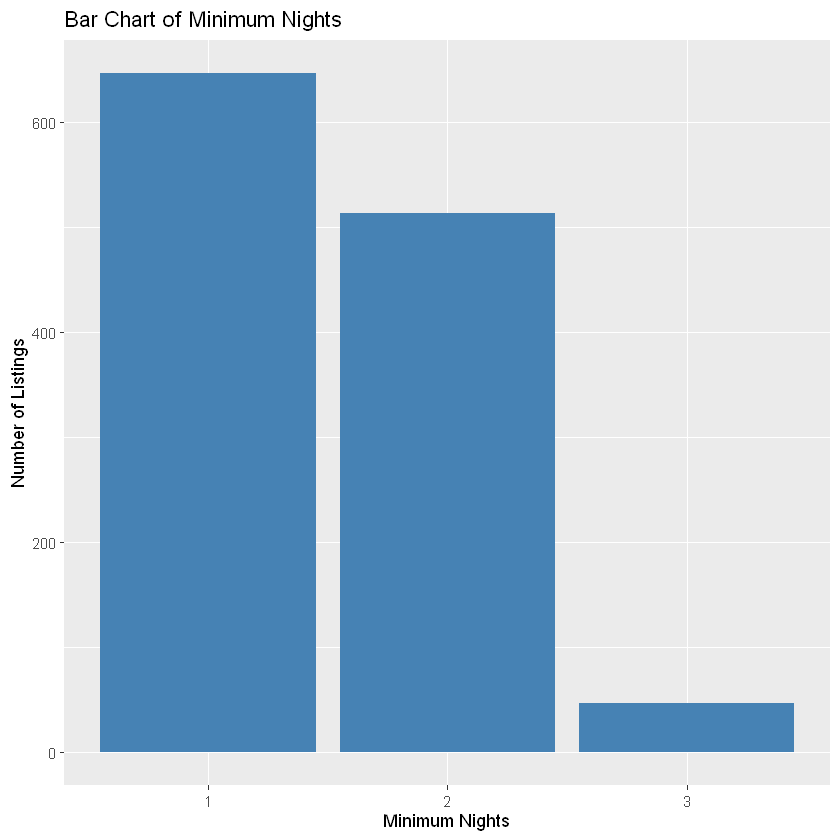

In [13]:
# Bar Chart of minimum_nights
ggplot(df, aes(x = factor(minimum_nights))) +
  geom_bar(fill = "steelblue") +
  labs(
    title = "Bar Chart of Minimum Nights",
    x = "Minimum Nights",
    y = "Number of Listings"
  )

`geom_smooth()` using formula = 'y ~ x'


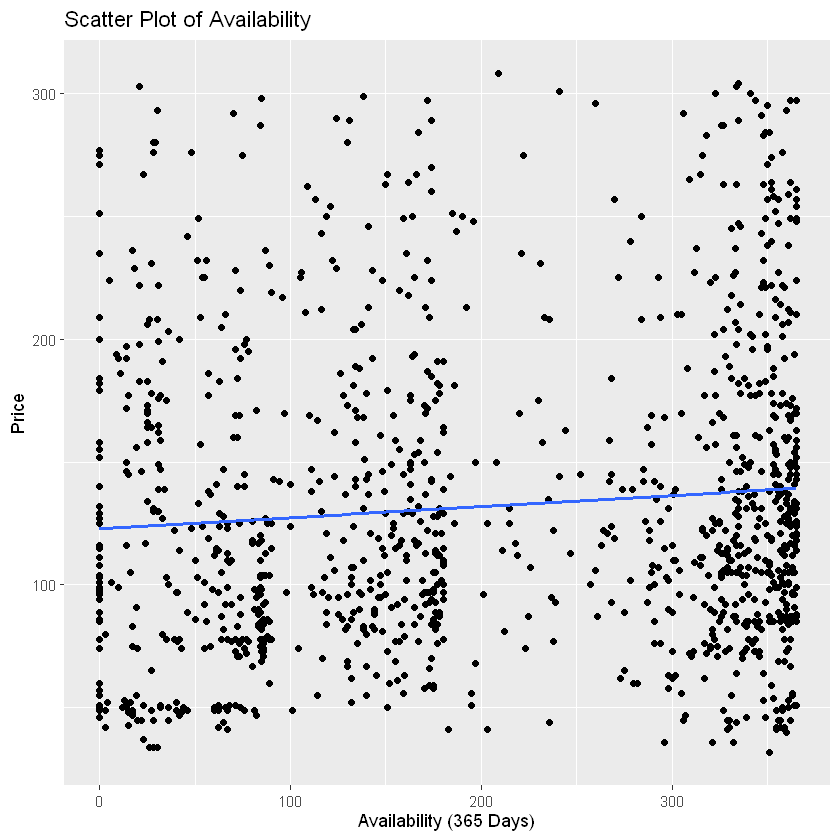

In [14]:
# Scatter Plot of availability_365
ggplot(df, aes(x = availability_365, y = price)) +
  geom_point() +
  geom_smooth(method = "lm", se = FALSE) +
  labs(
    title = "Scatter Plot of Availability",
    x = "Availability (365 Days)",
    y = "Price"
  )

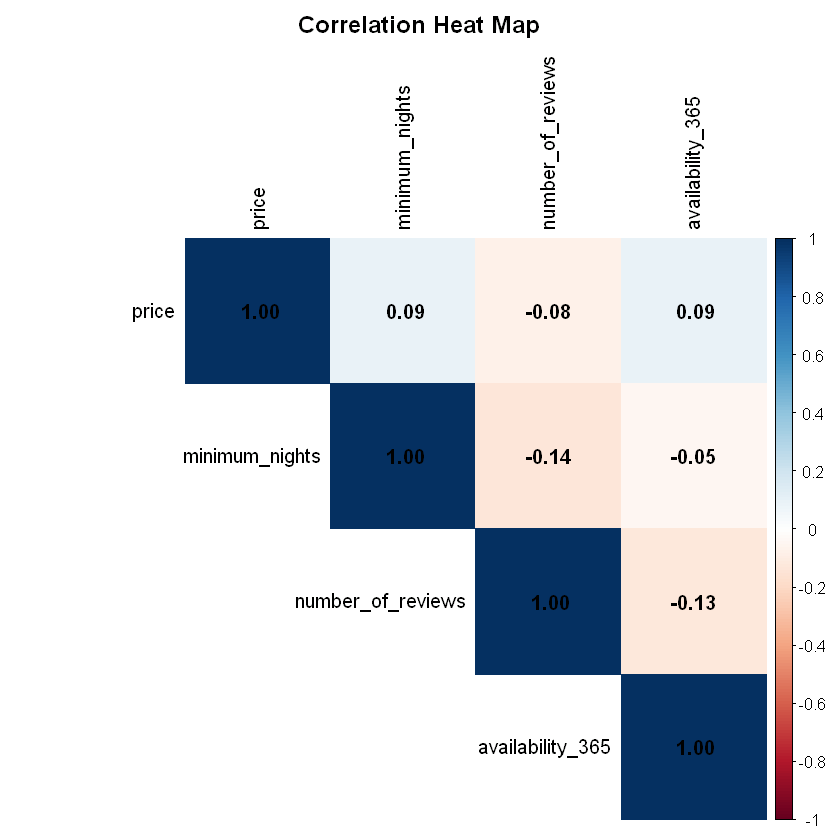

In [15]:
# Select the required columns
correlation_columns <- df[, c(
  "price",
  "minimum_nights",
  "number_of_reviews",
  "availability_365"
)]

# Calculate correlations
correlation_matrix <- cor(
  correlation_columns,
  use = "complete.obs"
)

# Create the heat map
corrplot(
  correlation_matrix,
  method = "color",
  type = "upper",
  addCoef.col = "black",
  tl.col = "black",
  title = "Correlation Heat Map",
  mar = c(0, 0, 2, 0)
)